# Data Understanding and Preparation 

Covers **Stage 1 (Dataset Understanding + EDA)** and **Stage 2 (Data Preparation)**. 
- Each stage below lists its **sub-tasks as a checklist**
- Complete every `# TODO` so each checklist item is satisfied
- Implement the reusable logic in `src/data_prep.py` and call it here so the same code backs your notebook and the later stages

**File ownership** — 
- *Provided (no change needed):* `config.py` (paths, target, column lists, params)
- *Provided to extend:* `src/data_prep.py` (function stubs)
- *You create:* the cells below + the report sections

**Business context:** flag diabetic inpatients at risk of 30-day readmission so care teams can intervene. The target is highly imbalanced (~9%), so metric choice and leakage prevention matter.

# Stage 1 - Business & Data Understanding, EDA, and Methodology  <font color="red">[20 marks]</font>

> **Stage 1 also has report-only tasks** graded from the MLOps report, not this notebook: **1.1 Business Understanding** (1.1.1–1.1.3) and **1.4 Methodology Design** (1.4.1–1.4.2).

In [1]:
%load_ext autoreload
%autoreload 2

import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import config as cfg
# TODO: load data/diabetic_data.csv treating '?' as NaN (na_values=['?']); print shape; head(3).

df = pd.read_csv("data/diabetic_data.csv", na_values='?')
print(f"Shape is {df.shape}\n\n")
print(df.head(3))

Shape is (101766, 50)


   encounter_id  patient_nbr             race  gender      age weight  \
0       2278392      8222157        Caucasian  Female   [0-10)    NaN   
1        149190     55629189        Caucasian  Female  [10-20)    NaN   
2         64410     86047875  AfricanAmerican  Female  [20-30)    NaN   

   admission_type_id  discharge_disposition_id  admission_source_id  \
0                  6                        25                    1   
1                  1                         1                    7   
2                  1                         1                    7   

   time_in_hospital  ... citoglipton insulin  glyburide-metformin  \
0                 1  ...          No      No                   No   
1                 3  ...          No      Up                   No   
2                 2  ...          No      No                   No   

   glipizide-metformin  glimepiride-pioglitazone  metformin-rosiglitazone  \
0                   No                      

## Stage 1.2 — Dataset Understanding <font color="red">[4 marks]</font>

- **1.2.1 — Dataset structure, target derivation & patients-vs-encounters [2]** — print the shape (~101,766 × 50), derive the target (`readmitted` `<30` → 1), and compare unique patients (`patient_nbr`) vs encounters.
- **1.2.2 — Feature types & data-quality / missing-value quantification [2]** — summarise feature types and build a per-column missing-value table with percentages (note `?` was loaded as NaN; e.g. `weight` ~97% missing).

In [2]:
df.columns

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='object')

Number of columns are 101766 and Number of rows are 50
Unique values in readmitted column ['NO' '>30' '<30']


 Patient Vs Encounters


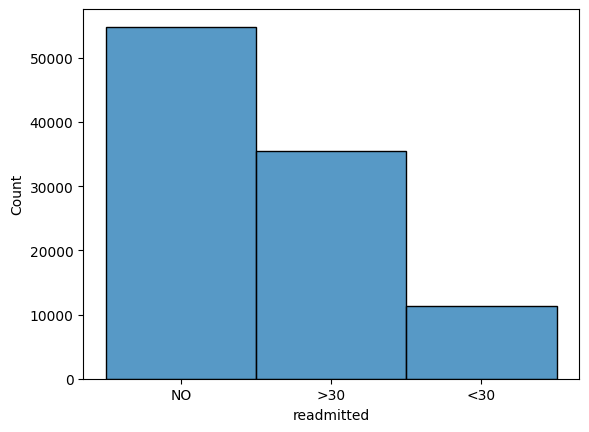

After change the unique values in readmitted column [0 1]


 Missing value count and percentage
                   Missing count  Missing %
race                        2273   2.233555
weight                     98569  96.858479
payer_code                 40256  39.557416
medical_specialty          49949  49.082208
diag_1                        21   0.020636
diag_2                       358   0.351787
diag_3                      1423   1.398306
max_glu_serum              96420  94.746772
A1Cresult                  84748  83.277322


 Dtype summary of all the columns
encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_

In [3]:
# TODO 1.2.1: print rows/columns; compare unique patients vs encounters; derive the binary target.
print(f"Number of columns are {df.shape[0]} and Number of rows are {df.shape[1]}")
print(f"Unique values in readmitted column {df['readmitted'].unique()}")

print("\n\n Patient Vs Encounters")
sns.histplot(df['readmitted'])
plt.show()

df['readmitted'] = (df['readmitted'] == '<30').astype(int)

print(f"After change the unique values in readmitted column {df['readmitted'].unique()}")
print("\n\n Missing value count and percentage")

# TODO 1.2.2: print feature dtypes summary and a missing-value table (count + pct) per column.
missing_table = pd.DataFrame({'Missing count': df.isna().sum(), 'Missing %': df.isna().mean()*100})
print(missing_table[missing_table['Missing count'] > 0])

print("\n\n Dtype summary of all the columns")
print(df.dtypes)

## Stage 1.3 — Exploratory Data Analysis <font color="red">[7 marks]</font>

- **1.3.1 — Univariate analysis [3]** — visualise the target imbalance and ≥3 numeric feature distributions, with brief observations.
- **1.3.2 — Bivariate analysis vs target [2]** — analyse ≥1 relationship to the target (e.g. readmission rate vs prior inpatient visits) and interpret it.
- **1.3.3 — Visualisations + written interpretation [2]** — clear, labelled plots; interpret each key finding in writing (see the interpretation cell below).

In [4]:
# Numeric columns in the table
col_numeric = df.select_dtypes(include="number").columns.tolist()
col_numeric

['encounter_id',
 'patient_nbr',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'number_diagnoses',
 'readmitted']

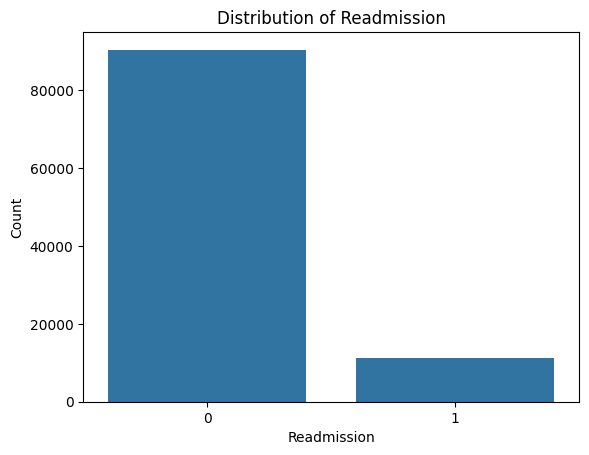

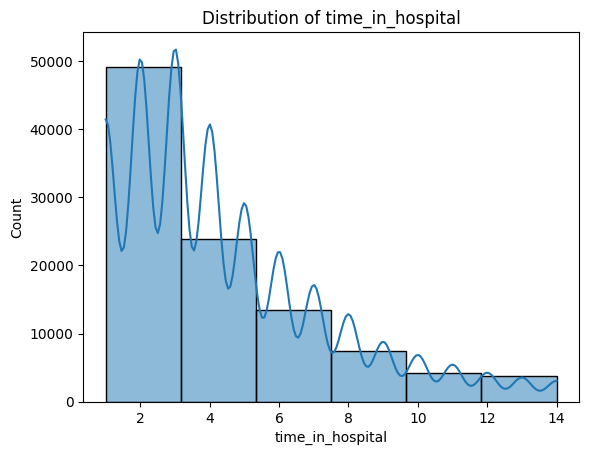

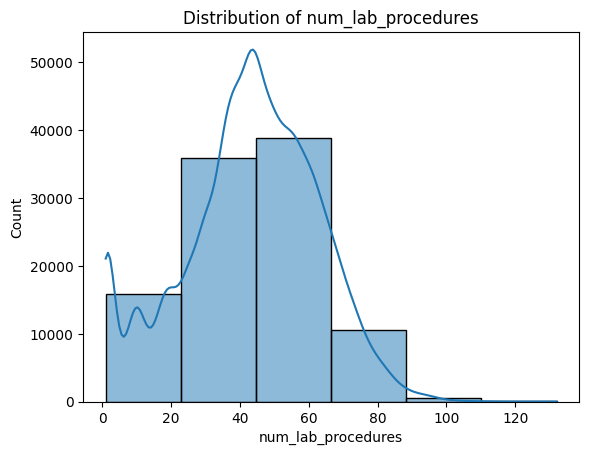

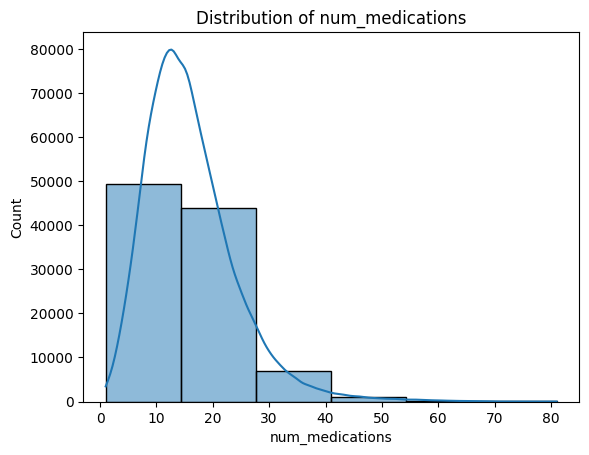

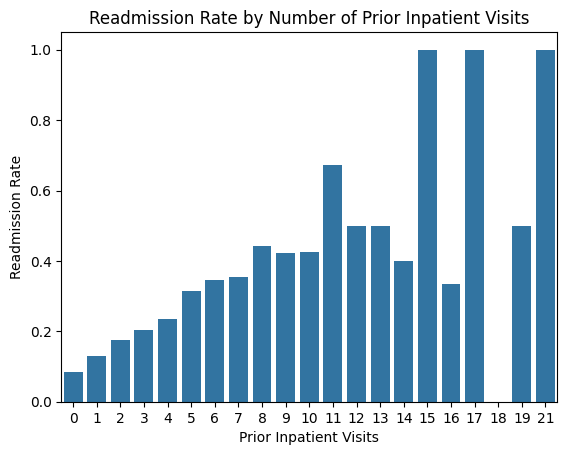

In [5]:
# TODO 1.3.1: plot the target imbalance + >=3 numeric distributions.
sns.countplot(data=df, x='readmitted')
plt.title('Distribution of Readmission')
plt.ylabel('Count')
plt.xlabel('Readmission')
plt.show()

col_num = ['time_in_hospital', 'num_lab_procedures', 'num_medications']

for c in col_num:
    sns.histplot(data=df, x=c, bins=6, kde=True)
    plt.title(f'Distribution of {c}')
    plt.ylabel('Count')
    plt.xlabel(f'{c}')
    plt.show()

# TODO 1.3.2: plot >=1 bivariate view vs the target (e.g. readmit rate by prior inpatient visits).
sns.barplot(data=df, x = 'number_inpatient', y = 'readmitted', ci=None)
plt.title('Readmission Rate by Number of Prior Inpatient Visits')
plt.ylabel('Readmission Rate')
plt.xlabel('Prior Inpatient Visits')
plt.show()

# TODO 1.3.3: ensure plots are labelled; record findings in the interpretation cell.
# Plots are labelled and the interpretation is mentioned in the next text box

### ✍️ Interpretation (1.3.3)
*TODO: what does the ~9% imbalance imply for metric choice? Which columns are unusable (e.g. weight ~97% missing) and why? What does the bivariate view tell you?*

Target imbalance
- Imbalance is high readmission is very less maybe close to 9%
- Accuracy is unreliable metric here because of imbalance
- Therefore, metrics that focus on the minority class, such as Precision-Recall AUC (PR-AUC), F1-Score, or Recall, must be used to properly evaluate the model's business value.

Unusable Column
- Based on the missing-value analysis, the weight column is heavily missing (~97%) and cannot be reliably imputed, making it unusable for modeling.
- Other columns with excessively high missing rates, such as payer_code and medical_specialty (around 40-50% missing).
- Should also be carefully evaluated for removal or require specialized handling, as standard imputation could introduce significant bias.

Univariate
- The univariate distributions show that features like time_in_hospital and num_medications are highly right-skewed
- most patients having short stays (1-4 days) and fewer medications (10-20), followed by a long tail of extreme values
- num_lab_procedures shows a wider, roughly bimodal spread

bivariate
- The bivariate analysis reveals a strong positive correlation between prior hospitalizations and future risk
- As a patient's number of prior inpatient visits increases, their 30-day readmission rate steadily climbs from less than 10% (for 0 prior visits) to over 40% (for 8+ prior visits)
- This indicates that number_inpatient will be a highly predictive feature for the model

## Stage 2 — Data Preparation  <font color="red">[25 marks]</font>

## Stage 2.1 — Data Cleaning <font color="red">[6 marks]</font>

Implement `clean()` in `src/data_prep.py`, then call it here.

- **2.1.1 — Missing value handling & invalid value treatment [2]** — `?`→NaN; drop `weight` and constant/zero-variance medication columns.
- **2.1.2 — Patient deduplication & removal of invalid records [2]** — keep the FIRST encounter per patient (`drop_duplicates('patient_nbr')`, prevents leakage); drop expired/hospice discharges (`discharge_disposition_id` ∈ {11,13,14,19,20,21}).
- **2.1.3 — Target variable creation & validation [2]** — build the binary target and validate its class balance (expect ~69,973 rows, ~9% positive).

In [6]:
# TODO (src/data_prep.py clean()): implement sub-tasks 2.1.1–2.1.3 above.
# TODO (here): clean = dp.clean(raw); print the resulting shape and target rate.

# Import data_prep
import src.data_prep as dp

# Load raw data with the func
df_test = dp.load_raw()

# Clean the datafram using clean function
clean = dp.clean(df_test)

# Print the shape
print(f"The cleaned version of the dataframe has shape {clean.shape}")
print(f"{clean['readmitted_30d'].sum()}")

The cleaned version of the dataframe has shape (69973, 38)
6277


## Stage 2.2 — Feature Engineering <font color="red">[8 marks]</font>

Implement `engineer_features()` in `src/data_prep.py`.

- **2.2.1 — ICD-9 diagnosis grouping into clinical categories [4]** — group `diag_1/2/3` into clinical categories (circulatory, respiratory, diabetes, injury, other) with a justified mapping.
- **2.2.2 — Additional engineered features, justified [4]** — ≥3 of {age midpoint, service_utilization, num_med_changes, medical_specialty top-k grouping}, each justified.

In [7]:
# TODO (src/data_prep.py engineer_features()): implement sub-tasks 2.2.1–2.2.2 above.
# TODO (here): fe = dp.engineer_features(clean); preview the new feature columns.

# Call the function to do feature engineering over clean dataframe
fe = dp.engineer_features(clean)

# check the output
fe[['diag_1', 'diag_2', 'diag_3', 'age', 'service_utilization', 'num_med_changes', 'medical_specialty']].head(5)

,diag_1,diag_2,diag_3,age,service_utilization,num_med_changes,medical_specialty
0,Diabetes,Other,Other,5,0,0,Other
1,Other,Diabetes,Other,15,0,1,Other
2,Other,Diabetes,Other,25,3,0,Other
3,Other,Diabetes,Circulatory,35,0,1,Other
4,Other,Other,Diabetes,45,0,0,Other


## Stage 2.3 — Feature Transformation <font color="red">[5 marks]</font>

Implement `build_preprocessor()` in `src/data_prep.py`.

- **2.3.1 — Numeric scaling & categorical encoding [3]** — numeric: median-impute + scale; categorical: impute + `OneHotEncoder(handle_unknown='ignore')`.
- **2.3.2 — Leakage-safe ColumnTransformer/Pipeline assembly [2]** — assemble ONE ColumnTransformer; do **not** fit it yet (fitting happens on the train split only, in 2.4).

In [8]:
# TODO (src/data_prep.py build_preprocessor()): implement sub-tasks 2.3.1–2.3.2 above.
# TODO (here): construct the (unfitted) preprocessor and show its structure.

# 1. Generate the feature lists from your engineered DataFrame ('fe')
numeric_cols, categorical_cols = dp.get_feature_lists(fe)

# 2. Construct the unfitted ColumnTransformer blueprint
preprocessor = dp.build_preprocessor(numeric_cols, categorical_cols)

# 3. Enable scikit-learn's visual pipeline display
from sklearn import set_config
set_config(display='diagram')

# 4. Display the structure (leaving the variable at the end outputs the diagram)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## Stage 2.4 — Validation & Splitting <font color="red">[6 marks]</font>

Implement `get_splits()` in `src/data_prep.py`.

- **2.4.1 — Stratified train/validation/test split created first [3]** — STRATIFIED split BEFORE any fitting (`random_state=42`; class ratio preserved).
- **2.4.2 — Leakage-safe fit-on-train + class-balance check [3]** — fit the preprocessor on TRAIN only, transform val/test; confirm the class ratio is preserved across splits.

In [9]:
# TODO (src/data_prep.py get_splits()): implement sub-tasks 2.4.1–2.4.2 above.
# TODO (here): create splits; fit preprocessor on train only; print split sizes,
#       feature count, and the class ratio per split (confirm no leakage).

# 1. Create the stratified splits
X_train, X_val, X_test, y_train, y_val, y_test = dp.get_splits(fe)

# 2. Fit the preprocessor on TRAIN only, then transform all splits
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_val_preprocessed = preprocessor.transform(X_val)
X_test_preprocessed = preprocessor.transform(X_test)

# 3. Print split sizes (Number of rows)
print("=== Split Sizes ===")
print(f"Train:      {X_train.shape[0]:,} rows")
print(f"Validation: {X_val.shape[0]:,} rows")
print(f"Test:       {X_test.shape[0]:,} rows")

# 4. Print feature count (After One-Hot Encoding expands the columns)
print("\n=== Feature Count ===")
print(f"Original features:    {X_train.shape[1]}")
print(f"Engineered features:  {X_train_preprocessed.shape[1]}")

# 5. Print class ratio per split to confirm stratification
print("\n=== Class Ratio (Readmission Rate) ===")
print(f"Train:      {y_train.mean():.4%} positive")
print(f"Validation: {y_val.mean():.4%} positive")
print(f"Test:       {y_test.mean():.4%} positive")

=== Split Sizes ===
Train:      44,782 rows
Validation: 11,196 rows
Test:       13,995 rows

=== Feature Count ===
Original features:    39
Engineered features:  115

=== Class Ratio (Readmission Rate) ===
Train:      8.9724% positive
Validation: 8.9675% positive
Test:       8.9675% positive
